In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import ConvexHull
import math
import time
import statistics
from scipy.spatial import Voronoi, voronoi_plot_2d
from matplotlib import pyplot as plt

def cartesian_to_polar(point, origin):
    #Convert Cartesian coordinates to polar coordinates with respect to a new origin.
    x, y = point
    x_p, y_p = origin
    dx, dy = x - x_p, y - y_p
    r = math.sqrt(dx**2 + dy**2)
    theta = math.atan2(dy, dx)
    return r, theta



# Finding the min angle at a given point x covering the convex hull is finding the max angle at x and any two hull verticies.

#First, we need a function to compute the angle at a point x, given two points y and z.

def compute_angleatx(x, y, z):
   
    def distance(p1, p2):
        return math.hypot(p2[0] - p1[0], p2[1] - p1[1])

    # Compute the lengths of the sides opposite to each vertex
    a = distance(y, z)  # Length opposite vertex x
    b = distance(x, z)  # Length opposite vertex y
    c = distance(x, y)  # Length opposite vertex z

    # Check for degenerate triangle
    #if a + b <= c or a + c <= b or b + c <= a:
        #raise ValueError("The points do not form a valid triangle.")

    if b != 0 and c!=0:
        triangle = (b**2 + c**2 - a**2) / (2 * b * c)
        
        if triangle>1:
            triangle = 1

        if triangle <-1:
            triangle = -1

        
        angle_x = math.acos(triangle)
    else:
        angle_x = 0
  

    return np.degrees(angle_x)

# Next function is for finding the min angle at a given point x covering the convex hull, which consists of finding the max angle at x and any two 
# hull verticies.
def MinAngle(hull_points,x):
    L=[]
    I=[]
    for i in range(len(hull_points)):
        for j in range(i+1,len(hull_points)):
            L.append(compute_angleatx(x, hull_points[i], hull_points[j]))
            I.append([i,j])
        
    minAngle = max(L)

    # Find the points satisfying the min angle with x
    max_index = L.index(minAngle)
    i1=I[max_index][0]
    i2=I[max_index][1]

    itemp1=i1
    itemp2=i2
    
    pi1=cartesian_to_polar(hull_points[i1],x)[1]
    pi2=cartesian_to_polar(hull_points[i2],x)[1]

    if pi1<0 and pi2<0:
        if pi2<pi1:
            i2=itemp1
            i1=itemp2

    if pi1>0 and pi2>0:
        if pi2<pi1:
            i2=itemp1
            i1=itemp2

    if pi1<0 and pi2>0:
        if pi1<-math.pi / 2:
            i2=itemp1
            i1=itemp2

    if pi1>0 and pi2<0:
        if pi1<math.pi / 2:
            i2=itemp1
            i1=itemp2

    
            
    P1=hull_points[i1]
    P2=hull_points[i2]
    return minAngle, P1, P2 #returns the min angle and the hull vertices satisfying minangle with x


#To visualize the angle and the vertices above we generate the line passing through P1, P2
def Line(P1,P2):
    x1, y1 = P1
    x2, y2 = P2

# Calculate the slope (m) and intercept (b)
    if x2 - x1 != 0:
        m = (y2 - y1) / (x2 - x1)
        b = y1 - m * x1
        # Generate x and y values for plotting
        x_values = np.linspace(min(x1, x2) - 200, max(x1, x2) + 1, 100)
        y_values = m * x_values + b
    else:
    # Handle vertical line
        m = None
        b = None
        x_values = np.full(100, x1)
        y_values = np.linspace(min(y1, y2) - 200, max(y1, y2) + 1, 100)
    return x_values, y_values


def Scoringhulls(HullsList,NonCov_coordinates):
    Scores=[]
    for i in HullsList:
        k=0
        for j in range(len(NonCov_coordinates)):
            if is_point_in_hull(NonCov_coordinates[j], i, tolerance=0):
                k+=1
            else:
                k=k
        Card_cov_sub=len()
        Scores.append(k)
        
    return Scores

#A function taking as input a black point, the covered blue points and returning subsets of points with sides removed, 
#iterated for a number of times equal to some "bound" .At each iteration we remove two points, one from the left and one from the right
def Subsets(BP,Cov_coordinates,bound):
    SubsetList=[]
    P=np.vstack([BP, Cov_coordinates])
    SubsetList.append(P)
    for i in range(bound):
        P1=MinAngle(Cov_coordinates,BP)[1]
        P2=MinAngle(Cov_coordinates,BP)[2]
        mask = ~(np.all(Cov_coordinates == np.array(P1), axis=1))
        Cov_coordinates = Cov_coordinates[mask]
        mask = ~(np.all(Cov_coordinates == np.array(P2), axis=1))
        Cov_coordinates = Cov_coordinates[mask]
        P=np.vstack([BP, Cov_coordinates])
        SubsetList.append(P)
    return SubsetList
#please note that the first entry in the list, i.e., Subsets(BP,Cov_coordinates,bound)[0] is the set consisting of 
    #ALL Cov_coordinates union the black point BP.

def LSubsets(BP,Cov_coordinates,bound):
    SubsetList=[]
    P=np.vstack([BP, Cov_coordinates])
    SubsetList.append(P)
    for i in range(bound):
        P1=MinAngle(Cov_coordinates,BP)[1]
        mask = ~(np.all(Cov_coordinates == np.array(P1), axis=1))
        Cov_coordinates = Cov_coordinates[mask]
        P=np.vstack([BP, Cov_coordinates])
        SubsetList.append(P)
    return SubsetList

def RSubsets(BP,Cov_coordinates,bound):
    SubsetList=[]
    P=np.vstack([BP, Cov_coordinates])
    SubsetList.append(P)
    for i in range(bound):
        P2=MinAngle(Cov_coordinates,BP)[2]
        mask = ~(np.all(Cov_coordinates == np.array(P2), axis=1))
        Cov_coordinates = Cov_coordinates[mask]
        P=np.vstack([BP, Cov_coordinates])
        SubsetList.append(P)
    return SubsetList


# We need a function taking as input list of subsets for a fixed black point and the set nonCov, 
# then returns a list of scores (we are interested in the min score) 
def Scoringhullssubset(subsets,NonCov_coordinates):
    Card_cov=len(subsets[0]-1)
    Scores=[]
    for i in subsets:
        if len(i)>3:
            hull = ConvexHull(i)
            Card_subset=len(i)-1
            k=0
            for j in range(len(NonCov_coordinates)):
                if is_point_in_hull(NonCov_coordinates[j], hull, tolerance=0):
                    k+=1
                else:
                    k=k
            S=k+(Card_cov-Card_subset)
            Scores.append(S)
        
        else:
            S=Card_cov-Card_subset
            Scores.append(S)
    return Scores

#Function to compute the scores of FBS_coordinates, the variable "bound" is used to precise the number of times we remove points from the sides
#At each iteration we remove two points, one from the left and one from the right
def Pot_FBS(FBS_coordinates,Cov_coordinates,NonCov_coordinates,bound):
    Scores=[]
    for i in FBS_coordinates:
        subsetlist=Subsets(i,Cov_coordinates,bound)
        t=min(Scoringhullssubset(subsetlist,NonCov_coordinates))
        Scores.append(t)
    return Scores
        

def Pot_FBSsides(FBS_coordinates,Cov_coordinates,NonCov_coordinates,bound):
    Scores=[]
    for i in FBS_coordinates:

        hull = ConvexHull(Cov_coordinates)
        
        if is_point_in_hull(i,hull,0):
            hulllist=[]
            hulllist.append(hull)
            subsetlist=LSubsets(i,Cov_coordinates,0)
            inHullScore=1
            t2=min(Scoringhullssubset(subsetlist,NonCov_coordinates))+inHullScore        
        else:
            inHullScore=0
            
            subsetlist=LSubsets(i,Cov_coordinates,bound)
            scores1=Scoringhullssubset(subsetlist,NonCov_coordinates)
            t=min(scores1)
            for j in range(len(scores1)):
                 if t==scores1[j]:
                     subsetlist2=RSubsets(i,subsetlist[j],min(bound, max(len(subsetlist[j])-1,0)))
                     t2=min(Scoringhullssubset(subsetlist2,NonCov_coordinates))+inHullScore
                     break
        Scores.append(t2)
    return Scores

# New hull Scoring 
### Fix a black point $P$, let $Cov$ be the set of blue points, $Noncov$ the set of yellow points.
### Above we considered $Hull_p(Cov)=Cvxhull(P \cup Cov)$, and our score is $Score(Hull_p(Cov))= \# (Noncov \cap Hull_p(Cov))$.
### Our goal now is to find a subset $SubCov\subseteq Cov$, such that
### $$Hull_p(SubCov)=Cvxhull(P \cup SubCov),$$ minimizing $Score(Hull_p(SubCov))+ card(Cov)-card(SubCov),$ where $Score(Hull_p(SubCov))= \# (Noncov \cap Hull_p(SubCov))$.
### To avoid considering all possible subsets, thus, we consider subsets with boundary points removed.

predicted [580. 400.] real location [590.776, 322.766] Error 77.982132133
HP predicted [544. 584.] real location [590.776, 322.766] Error 265.388765648
predicted [593.33333333 386.66666667] real location [573.403, 368.368] Error 27.056596027
HP predicted [480. 340.] real location [573.403, 368.368] Error 97.615899489
predicted [580. 360.] real location [555.745, 414.719] Error 59.853771694
HP predicted [540. 480.] real location [555.745, 414.719] Error 67.152914948
predicted [540. 420.] real location [537.945, 461.443] Error 41.493918518
HP predicted [546.66666667 460.        ] real location [537.945, 461.443] Error 8.840232941
predicted [500. 500.] real location [520.144, 508.167] Error 21.736619447
HP predicted [780. 900.] real location [520.144, 508.167] Error 470.168310954
predicted [540. 460.] real location [502.344, 554.891] Error 102.089549989
HP predicted [640. 760.] real location [502.344, 554.891] Error 247.019991533
predicted [440. 500.] real location [484.543, 601.615] Erro

C:\Users\Omistaja\AppData\Local\Temp\ipykernel_7532\568097070.py:1174: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(12, 8))


predicted [580. 460.] real location [555.745, 414.719] Error 51.368024938
HP predicted [480. 760.] real location [555.745, 414.719] Error 353.491547262
predicted [600. 440.] real location [537.945, 461.443] Error 65.655352211
HP predicted [460. 670.] real location [537.945, 461.443] Error 222.646458032
predicted [520. 540.] real location [520.144, 508.167] Error 31.833325698
HP predicted [480.         806.66666667] real location [520.144, 508.167] Error 301.186971392
predicted [560. 460.] real location [502.344, 554.891] Error 111.033851671
HP predicted [520. 560.] real location [502.344, 554.891] Error 18.380321461
predicted [580. 620.] real location [484.543, 601.615] Error 97.211352598
HP predicted [430. 960.] real location [484.543, 601.615] Error 362.511719913
predicted [440. 540.] real location [466.743, 648.339] Error 111.590891071
HP predicted [180. 920.] real location [466.743, 648.339] Error 394.995249301
predicted [500. 660.] real location [448.942, 695.064] Error 61.9387072

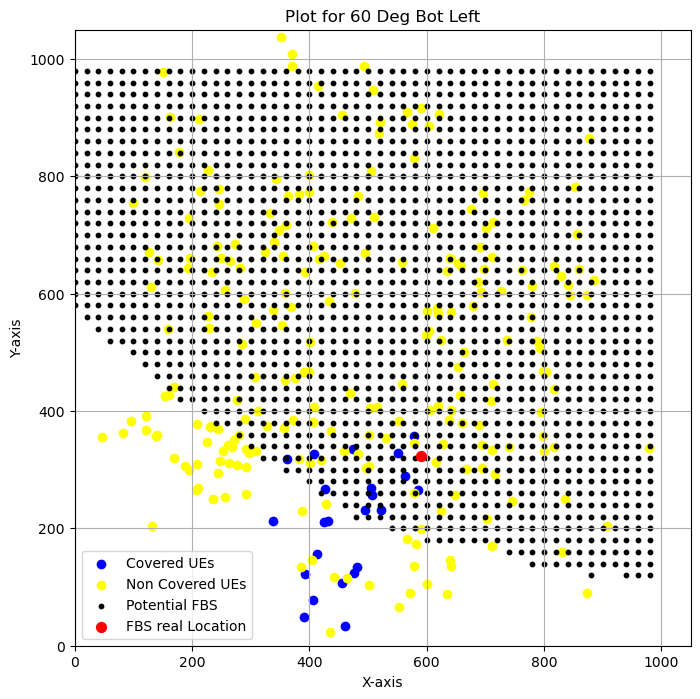

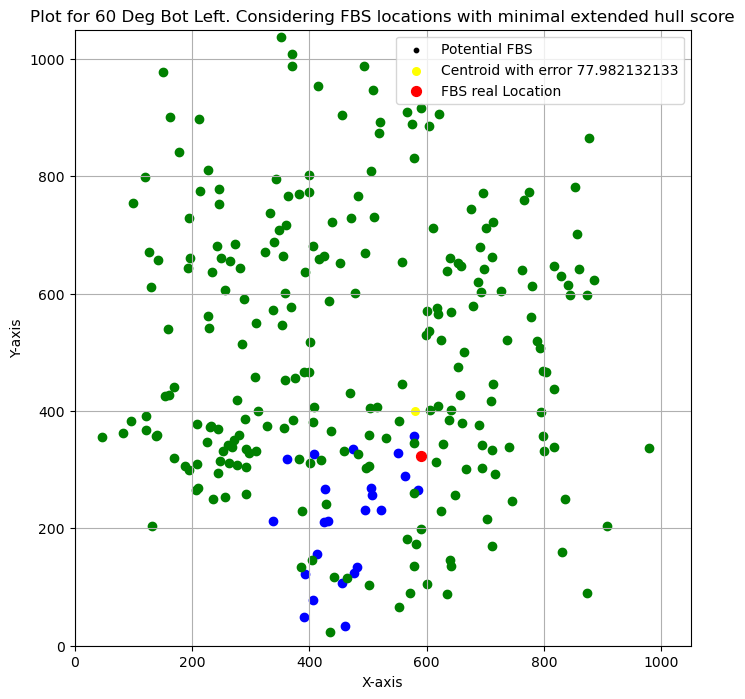

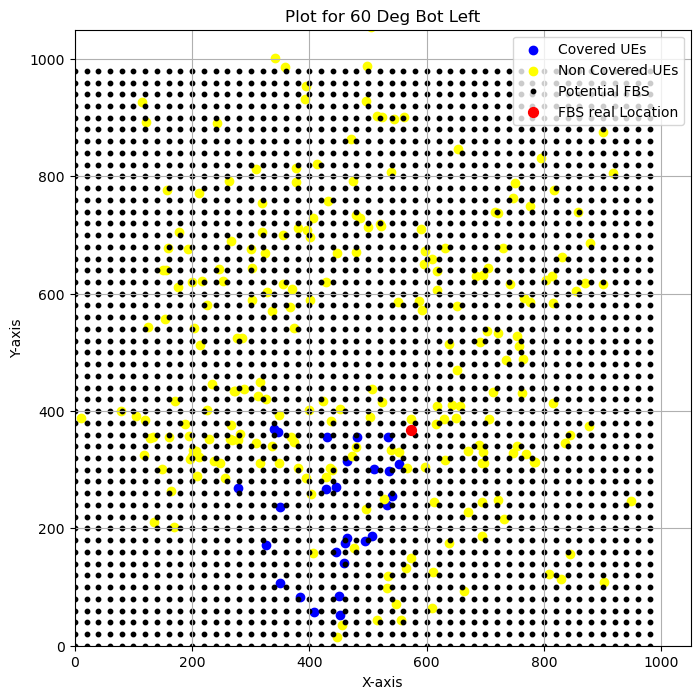

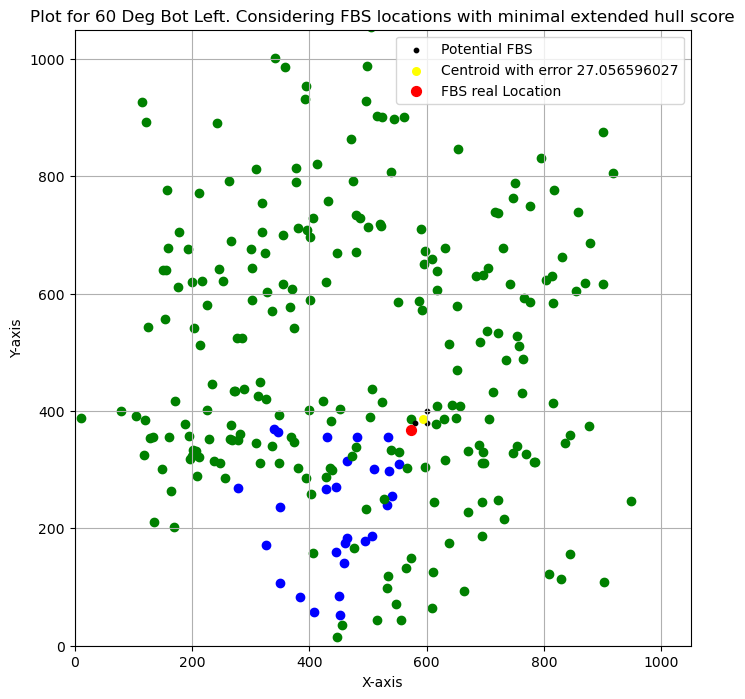

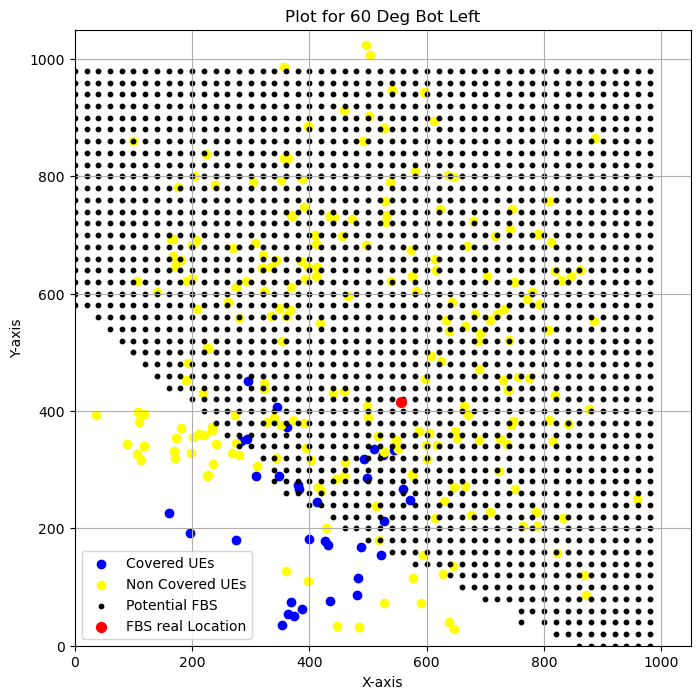

...

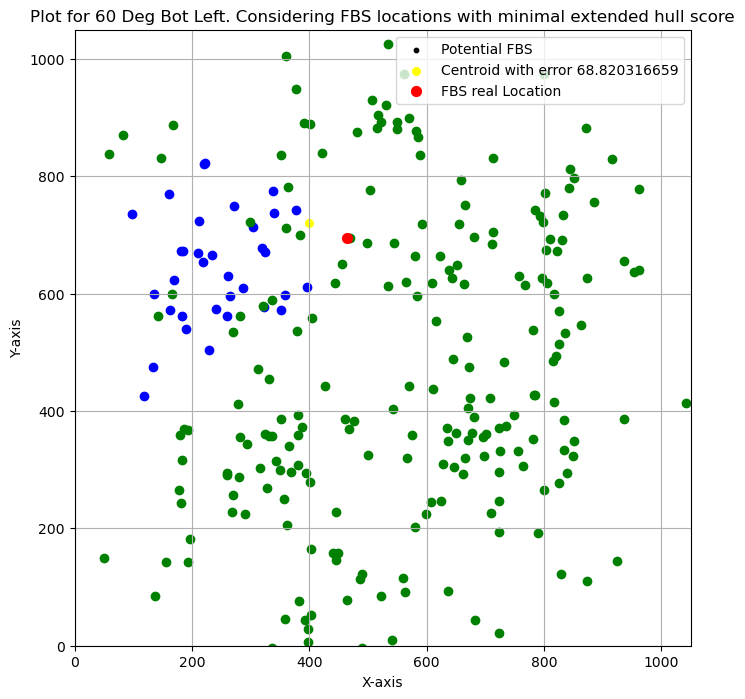

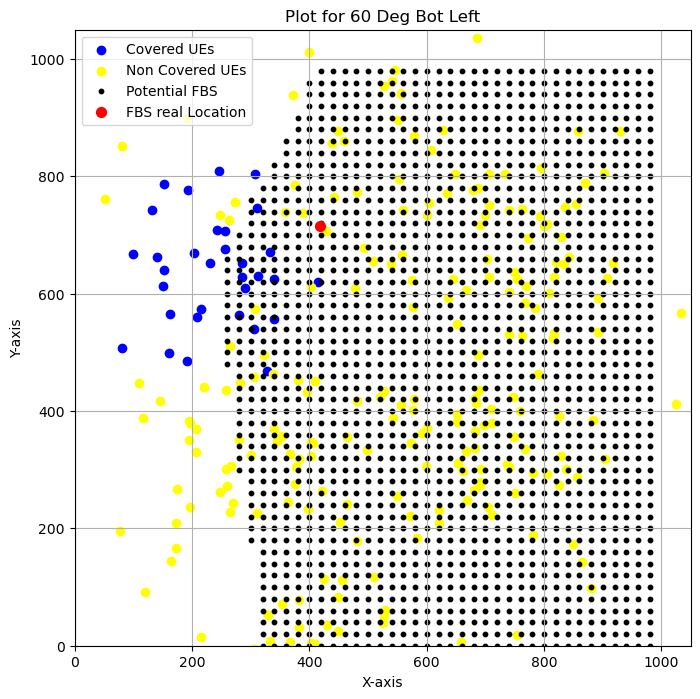

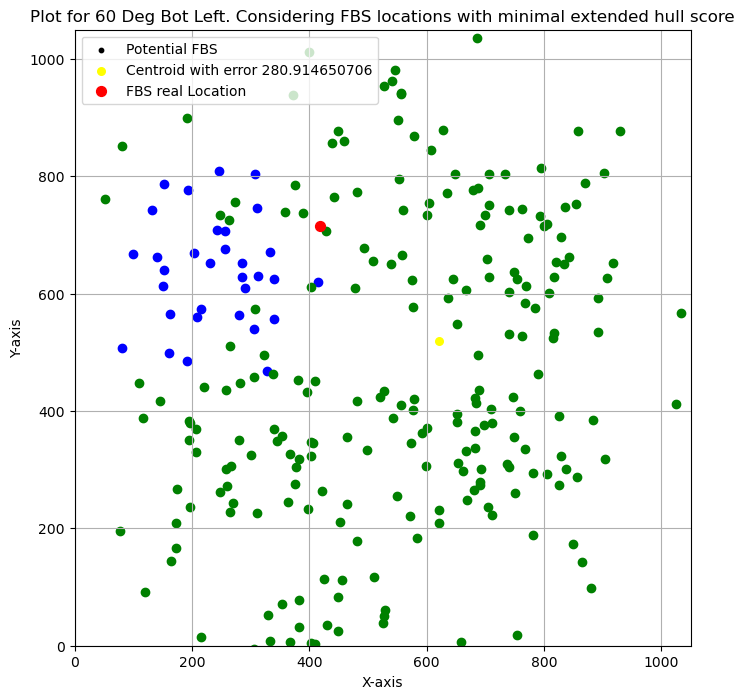

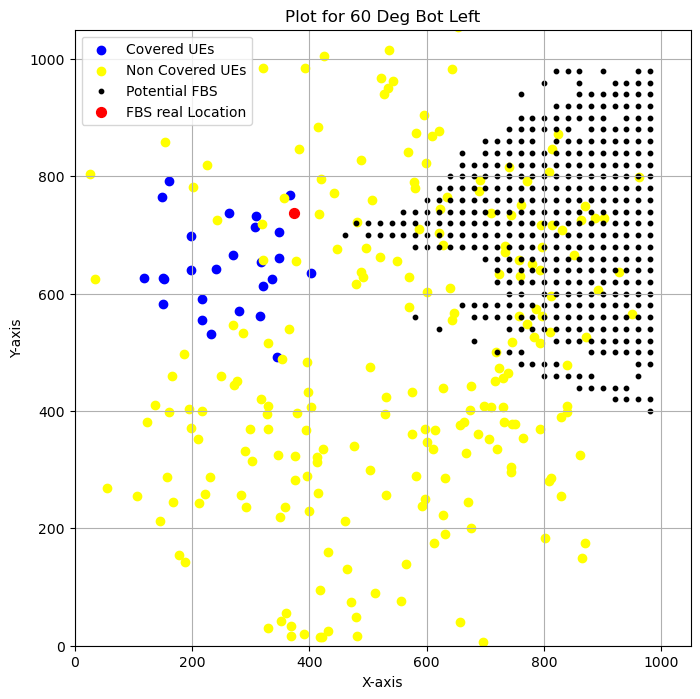

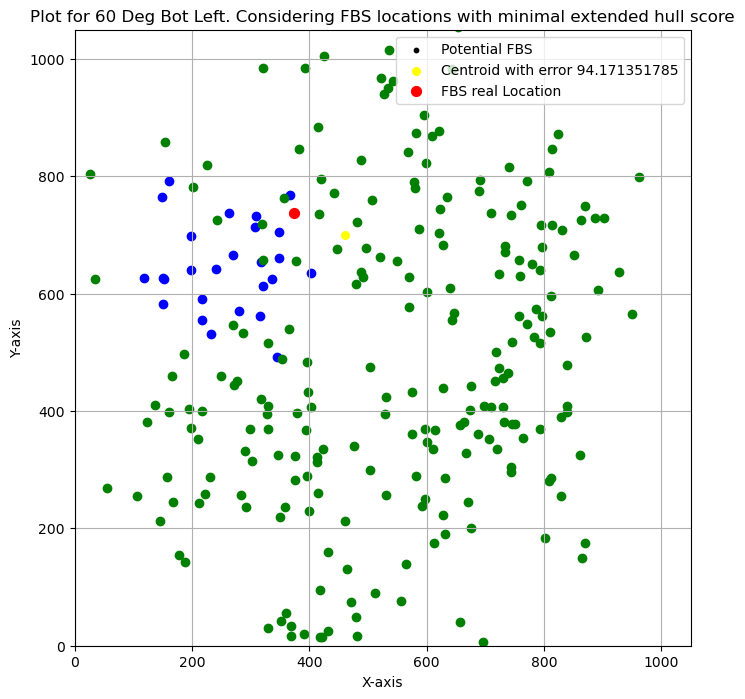

In [3]:
for Run in [3, 4, 5]:
    for Ang in [0, 1, 2, 3, 4, 5]:
        for Timer in [0, 1, 2, 3, 4, 5, 6, 7, 8]:
            if Run == 3:
#                pass  # replace with your actual code            if Run == 3:
                if Ang == 0:
                    if Timer == 0:
                        dffbs = pd.read_csv('Score120GGPMove0R3A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove0R3A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove0R3A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove0R3A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 1:
                        dffbs = pd.read_csv('Score120GGPMove1R3A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove1R3A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove1R3A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove1R3A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 2:
                        dffbs = pd.read_csv('Score120GGPMove2R3A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove2R3A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove2R3A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove2R3A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 3:
                        dffbs = pd.read_csv('Score120GGPMove3R3A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove3R3A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove3R3A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove3R3A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 4:
                        dffbs = pd.read_csv('Score120GGPMove4R3A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove4R3A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove4R3A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove4R3A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 5:
                        dffbs = pd.read_csv('Score120GGPMove5R3A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove5R3A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove5R3A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove5R3A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 6:
                        dffbs = pd.read_csv('Score120GGPMove6R3A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove6R3A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove6R3A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove6R3A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 7:
                        dffbs = pd.read_csv('Score120GGPMove7R3A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove7R3A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove7R3A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove7R3A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 8:
                        dffbs = pd.read_csv('Score120GGPMove8R3A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove8R3A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove8R3A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove8R3A0', header=None, names=['coor'], delimiter=',')
        
        
        
        
        
                if Ang == 1:
                    if Timer == 0:
                        dffbs = pd.read_csv('Score120GGPMove0R3A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove0R3A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove0R3A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove0R3A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 1:
                        dffbs = pd.read_csv('Score120GGPMove1R3A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove1R3A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove1R3A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove1R3A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 2:
                        dffbs = pd.read_csv('Score120GGPMove2R3A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove2R3A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove2R3A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove2R3A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 3:
                        dffbs = pd.read_csv('Score120GGPMove3R3A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove3R3A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove3R3A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove3R3A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 4:
                        dffbs = pd.read_csv('Score120GGPMove4R3A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove4R3A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove4R3A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove4R3A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 5:
                        dffbs = pd.read_csv('Score120GGPMove5R3A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove5R3A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove5R3A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove5R3A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 6:
                        dffbs = pd.read_csv('Score120GGPMove6R3A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove6R3A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove6R3A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove6R3A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 7:
                        dffbs = pd.read_csv('Score120GGPMove7R3A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove7R3A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove7R3A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove7R3A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 8:
                        dffbs = pd.read_csv('Score120GGPMove8R3A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove8R3A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove8R3A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove8R3A1', header=None, names=['coor'], delimiter=',')
        
        
        
                        
                
                if Ang == 2:
                    if Timer == 0:
                        dffbs = pd.read_csv('Score120GGPMove0R3A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove0R3A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove0R3A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove0R3A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 1:
                        dffbs = pd.read_csv('Score120GGPMove1R3A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove1R3A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove1R3A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove1R3A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 2:
                        dffbs = pd.read_csv('Score120GGPMove2R3A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove2R3A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove2R3A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove2R3A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 3:
                        dffbs = pd.read_csv('Score120GGPMove3R3A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove3R3A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove3R3A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove3R3A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 4:
                        dffbs = pd.read_csv('Score120GGPMove4R3A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove4R3A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove4R3A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove4R3A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 5:
                        dffbs = pd.read_csv('Score120GGPMove5R3A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove5R3A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove5R3A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove5R3A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 6:
                        dffbs = pd.read_csv('Score120GGPMove6R3A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove6R3A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove6R3A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove6R3A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 7:
                        dffbs = pd.read_csv('Score120GGPMove7R3A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove7R3A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove7R3A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove7R3A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 8:
                        dffbs = pd.read_csv('Score120GGPMove8R3A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove8R3A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove8R3A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove8R3A2', header=None, names=['coor'], delimiter=',')
        
        
        
        
        
        
                if Ang == 3:
                    if Timer == 0:
                        dffbs = pd.read_csv('Score120GGPMove0R3A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove0R3A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove0R3A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove0R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 1:
                        dffbs = pd.read_csv('Score120GGPMove1R3A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove1R3A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove1R3A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove1R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 2:
                        dffbs = pd.read_csv('Score120GGPMove2R3A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove2R3A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove2R3A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove2R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 3:
                        dffbs = pd.read_csv('Score120GGPMove3R3A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove3R3A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove3R3A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove3R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 4:
                        dffbs = pd.read_csv('Score120GGPMove4R3A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove4R3A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove4R3A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove4R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 5:
                        dffbs = pd.read_csv('Score120GGPMove5R3A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove5R3A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove5R3A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove5R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 6:
                        dffbs = pd.read_csv('Score120GGPMove6R3A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove6R3A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove6R3A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove6R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 7:
                        dffbs = pd.read_csv('Score120GGPMove7R3A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove7R3A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove7R3A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove7R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 8:
                        dffbs = pd.read_csv('Score120GGPMove8R3A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove8R3A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove8R3A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove8R3A3', header=None, names=['coor'], delimiter=',')
        
        
        
        
        
        
                if Ang == 4:
                    if Timer == 0:
                        dffbs = pd.read_csv('Score120GGPMove0R3A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove0R3A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove0R3A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove0R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 1:
                        dffbs = pd.read_csv('Score120GGPMove1R3A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove1R3A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove1R3A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove1R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 2:
                        dffbs = pd.read_csv('Score120GGPMove2R3A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove2R3A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove2R3A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove2R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 3:
                        dffbs = pd.read_csv('Score120GGPMove3R3A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove3R3A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove3R3A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove3R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 4:
                        dffbs = pd.read_csv('Score120GGPMove4R3A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove4R3A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove4R3A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove4R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 5:
                        dffbs = pd.read_csv('Score120GGPMove5R3A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove5R3A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove5R3A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove5R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 6:
                        dffbs = pd.read_csv('Score120GGPMove6R3A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove6R3A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove6R3A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove6R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 7:
                        dffbs = pd.read_csv('Score120GGPMove7R3A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove7R3A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove7R3A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove7R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 8:
                        dffbs = pd.read_csv('Score120GGPMove8R3A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove8R3A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove8R3A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove8R3A3', header=None, names=['coor'], delimiter=',')
        
        
        
        
                if Ang == 5:
                    if Timer == 0:
                        dffbs = pd.read_csv('Score120GGPMove0R3A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove0R3A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove0R3A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove0R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 1:
                        dffbs = pd.read_csv('Score120GGPMove1R3A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove1R3A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove1R3A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove1R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 2:
                        dffbs = pd.read_csv('Score120GGPMove2R3A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove2R3A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove2R3A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove2R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 3:
                        dffbs = pd.read_csv('Score120GGPMove3R3A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove3R3A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove3R3A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove3R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 4:
                        dffbs = pd.read_csv('Score120GGPMove4R3A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove4R3A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove4R3A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove4R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 5:
                        dffbs = pd.read_csv('Score120GGPMove5R3A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove5R3A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove5R3A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove5R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 6:
                        dffbs = pd.read_csv('Score120GGPMove6R3A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove6R3A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove6R3A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove6R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 7:
                        dffbs = pd.read_csv('Score120GGPMove7R3A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove7R3A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove7R3A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove7R3A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 8:
                        dffbs = pd.read_csv('Score120GGPMove8R3A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove8R3A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove8R3A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove8R3A3', header=None, names=['coor'], delimiter=',')
        
    
    
    
            if Run == 4: 
    
    
    
                if Ang == 0:
                    if Timer == 0:
                        dffbs = pd.read_csv('Score120GGPMove0R4A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove0R4A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove0R4A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove0R4A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 1:
                        dffbs = pd.read_csv('Score120GGPMove1R4A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove1R4A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove1R4A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove1R4A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 2:
                        dffbs = pd.read_csv('Score120GGPMove2R4A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove2R4A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove2R4A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove2R4A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 3:
                        dffbs = pd.read_csv('Score120GGPMove3R4A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove3R4A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove3R4A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove3R4A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 4:
                        dffbs = pd.read_csv('Score120GGPMove4R4A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove4R4A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove4R4A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove4R4A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 5:
                        dffbs = pd.read_csv('Score120GGPMove5R4A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove5R4A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove5R4A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove5R4A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 6:
                        dffbs = pd.read_csv('Score120GGPMove6R4A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove6R4A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove6R4A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove6R4A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 7:
                        dffbs = pd.read_csv('Score120GGPMove7R4A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove7R4A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove7R4A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove7R4A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 8:
                        dffbs = pd.read_csv('Score120GGPMove8R4A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove8R4A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove8R4A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove8R4A0', header=None, names=['coor'], delimiter=',')
        
        
        
        
        
                if Ang == 1:
                    if Timer == 0:
                        dffbs = pd.read_csv('Score120GGPMove0R4A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove0R4A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove0R4A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove0R4A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 1:
                        dffbs = pd.read_csv('Score120GGPMove1R4A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove1R4A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove1R4A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove1R4A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 2:
                        dffbs = pd.read_csv('Score120GGPMove2R4A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove2R4A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove2R4A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove2R4A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 3:
                        dffbs = pd.read_csv('Score120GGPMove3R4A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove3R4A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove3R4A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove3R4A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 4:
                        dffbs = pd.read_csv('Score120GGPMove4R4A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove4R4A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove4R4A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove4R4A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 5:
                        dffbs = pd.read_csv('Score120GGPMove5R4A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove5R4A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove5R4A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove5R4A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 6:
                        dffbs = pd.read_csv('Score120GGPMove6R4A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove6R4A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove6R4A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove6R4A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 7:
                        dffbs = pd.read_csv('Score120GGPMove7R4A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove7R4A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove7R4A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove7R4A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 8:
                        dffbs = pd.read_csv('Score120GGPMove8R4A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove8R4A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove8R4A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove8R4A1', header=None, names=['coor'], delimiter=',')
        
        
        
                        
                
                if Ang == 2:
                    if Timer == 0:
                        dffbs = pd.read_csv('Score120GGPMove0R4A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove0R4A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove0R4A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove0R4A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 1:
                        dffbs = pd.read_csv('Score120GGPMove1R4A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove1R4A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove1R4A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove1R4A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 2:
                        dffbs = pd.read_csv('Score120GGPMove2R4A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove2R4A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove2R4A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove2R4A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 3:
                        dffbs = pd.read_csv('Score120GGPMove3R4A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove3R4A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove3R4A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove3R4A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 4:
                        dffbs = pd.read_csv('Score120GGPMove4R4A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove4R4A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove4R4A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove4R4A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 5:
                        dffbs = pd.read_csv('Score120GGPMove5R4A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove5R4A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove5R4A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove5R4A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 6:
                        dffbs = pd.read_csv('Score120GGPMove6R4A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove6R4A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove6R4A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove6R4A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 7:
                        dffbs = pd.read_csv('Score120GGPMove7R4A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove7R4A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove7R4A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove7R4A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 8:
                        dffbs = pd.read_csv('Score120GGPMove8R4A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove8R4A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove8R4A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove8R4A2', header=None, names=['coor'], delimiter=',')
        
        
        
        
        
        
                if Ang == 3:
                    if Timer == 0:
                        dffbs = pd.read_csv('Score120GGPMove0R4A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove0R4A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove0R4A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove0R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 1:
                        dffbs = pd.read_csv('Score120GGPMove1R4A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove1R4A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove1R4A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove1R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 2:
                        dffbs = pd.read_csv('Score120GGPMove2R4A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove2R4A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove2R4A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove2R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 3:
                        dffbs = pd.read_csv('Score120GGPMove3R4A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove3R4A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove3R4A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove3R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 4:
                        dffbs = pd.read_csv('Score120GGPMove4R4A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove4R4A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove4R4A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove4R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 5:
                        dffbs = pd.read_csv('Score120GGPMove5R4A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove5R4A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove5R4A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove5R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 6:
                        dffbs = pd.read_csv('Score120GGPMove6R4A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove6R4A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove6R4A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove6R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 7:
                        dffbs = pd.read_csv('Score120GGPMove7R4A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove7R4A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove7R4A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove7R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 8:
                        dffbs = pd.read_csv('Score120GGPMove8R4A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove8R4A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove8R4A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove8R4A3', header=None, names=['coor'], delimiter=',')
        
        
        
        
        
        
                if Ang == 4:
                    if Timer == 0:
                        dffbs = pd.read_csv('Score120GGPMove0R4A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove0R4A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove0R4A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove0R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 1:
                        dffbs = pd.read_csv('Score120GGPMove1R4A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove1R4A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove1R4A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove1R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 2:
                        dffbs = pd.read_csv('Score120GGPMove2R4A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove2R4A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove2R4A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove2R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 3:
                        dffbs = pd.read_csv('Score120GGPMove3R4A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove3R4A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove3R4A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove3R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 4:
                        dffbs = pd.read_csv('Score120GGPMove4R4A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove4R4A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove4R4A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove4R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 5:
                        dffbs = pd.read_csv('Score120GGPMove5R4A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove5R4A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove5R4A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove5R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 6:
                        dffbs = pd.read_csv('Score120GGPMove6R4A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove6R4A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove6R4A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove6R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 7:
                        dffbs = pd.read_csv('Score120GGPMove7R4A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove7R4A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove7R4A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove7R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 8:
                        dffbs = pd.read_csv('Score120GGPMove8R4A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove8R4A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove8R4A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove8R4A3', header=None, names=['coor'], delimiter=',')
        
        
        
        
                if Ang == 5:
                    if Timer == 0:
                        dffbs = pd.read_csv('Score120GGPMove0R4A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove0R4A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove0R4A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove0R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 1:
                        dffbs = pd.read_csv('Score120GGPMove1R4A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove1R4A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove1R4A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove1R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 2:
                        dffbs = pd.read_csv('Score120GGPMove2R4A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove2R4A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove2R4A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove2R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 3:
                        dffbs = pd.read_csv('Score120GGPMove3R4A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove3R4A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove3R4A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove3R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 4:
                        dffbs = pd.read_csv('Score120GGPMove4R4A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove4R4A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove4R4A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove4R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 5:
                        dffbs = pd.read_csv('Score120GGPMove5R4A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove5R4A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove5R4A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove5R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 6:
                        dffbs = pd.read_csv('Score120GGPMove6R4A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove6R4A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove6R4A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove6R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 7:
                        dffbs = pd.read_csv('Score120GGPMove7R4A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove7R4A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove7R4A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove7R4A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 8:
                        dffbs = pd.read_csv('Score120GGPMove8R4A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove8R4A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove8R4A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove8R4A3', header=None, names=['coor'], delimiter=',')
       
    
    
    
    
    
    
            if Run == 5: 
       
              
        
        
        
        
                if Ang == 0:
                    if Timer == 0:
                        dffbs = pd.read_csv('Score120GGPMove0R5A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove0R5A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove0R5A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove0R5A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 1:
                        dffbs = pd.read_csv('Score120GGPMove1R5A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove1R5A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove1R5A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove1R5A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 2:
                        dffbs = pd.read_csv('Score120GGPMove2R5A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove2R5A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove2R5A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove2R5A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 3:
                        dffbs = pd.read_csv('Score120GGPMove3R5A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove3R5A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove3R5A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove3R5A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 4:
                        dffbs = pd.read_csv('Score120GGPMove4R5A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove4R5A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove4R5A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove4R5A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 5:
                        dffbs = pd.read_csv('Score120GGPMove5R5A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove5R5A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove5R5A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove5R5A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 6:
                        dffbs = pd.read_csv('Score120GGPMove6R5A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove6R5A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove6R5A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove6R5A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 7:
                        dffbs = pd.read_csv('Score120GGPMove7R5A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove7R5A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove7R5A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove7R5A0', header=None, names=['coor'], delimiter=',')
                    if Timer == 8:
                        dffbs = pd.read_csv('Score120GGPMove8R5A0', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove8R5A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove8R5A0', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove8R5A0', header=None, names=['coor'], delimiter=',')
        
        
        
        
        
                if Ang == 1:
                    if Timer == 0:
                        dffbs = pd.read_csv('Score120GGPMove0R5A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove0R5A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove0R5A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove0R5A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 1:
                        dffbs = pd.read_csv('Score120GGPMove1R5A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove1R5A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove1R5A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove1R5A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 2:
                        dffbs = pd.read_csv('Score120GGPMove2R5A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove2R5A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove2R5A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove2R5A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 3:
                        dffbs = pd.read_csv('Score120GGPMove3R5A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove3R5A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove3R5A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove3R5A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 4:
                        dffbs = pd.read_csv('Score120GGPMove4R5A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove4R5A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove4R5A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove4R5A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 5:
                        dffbs = pd.read_csv('Score120GGPMove5R5A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove5R5A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove5R5A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove5R5A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 6:
                        dffbs = pd.read_csv('Score120GGPMove6R5A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove6R5A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove6R5A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove6R5A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 7:
                        dffbs = pd.read_csv('Score120GGPMove7R5A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove7R5A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove7R5A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove7R5A1', header=None, names=['coor'], delimiter=',')
                    if Timer == 8:
                        dffbs = pd.read_csv('Score120GGPMove8R5A1', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove8R5A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove8R5A1', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove8R5A1', header=None, names=['coor'], delimiter=',')
        
        
        
                        
                
                if Ang == 2:
                    if Timer == 0:
                        dffbs = pd.read_csv('Score120GGPMove0R5A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove0R5A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove0R5A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove0R5A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 1:
                        dffbs = pd.read_csv('Score120GGPMove1R5A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove1R5A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove1R5A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove1R5A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 2:
                        dffbs = pd.read_csv('Score120GGPMove2R5A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove2R5A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove2R5A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove2R5A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 3:
                        dffbs = pd.read_csv('Score120GGPMove3R5A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove3R5A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove3R5A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove3R5A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 4:
                        dffbs = pd.read_csv('Score120GGPMove4R5A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove4R5A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove4R5A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove4R5A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 5:
                        dffbs = pd.read_csv('Score120GGPMove5R5A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove5R5A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove5R5A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove5R5A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 6:
                        dffbs = pd.read_csv('Score120GGPMove6R5A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove6R5A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove6R5A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove6R5A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 7:
                        dffbs = pd.read_csv('Score120GGPMove7R5A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove7R5A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove7R5A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove7R5A2', header=None, names=['coor'], delimiter=',')
                    if Timer == 8:
                        dffbs = pd.read_csv('Score120GGPMove8R5A2', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove8R5A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove8R5A2', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove8R5A2', header=None, names=['coor'], delimiter=',')
        
        
        
        
        
        
                if Ang == 3:
                    if Timer == 0:
                        dffbs = pd.read_csv('Score120GGPMove0R5A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove0R5A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove0R5A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove0R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 1:
                        dffbs = pd.read_csv('Score120GGPMove1R5A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove1R5A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove1R5A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove1R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 2:
                        dffbs = pd.read_csv('Score120GGPMove2R5A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove2R5A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove2R5A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove2R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 3:
                        dffbs = pd.read_csv('Score120GGPMove3R5A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove3R5A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove3R5A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove3R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 4:
                        dffbs = pd.read_csv('Score120GGPMove4R5A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove4R5A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove4R5A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove4R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 5:
                        dffbs = pd.read_csv('Score120GGPMove5R5A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove5R5A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove5R5A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove5R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 6:
                        dffbs = pd.read_csv('Score120GGPMove6R5A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove6R5A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove6R5A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove6R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 7:
                        dffbs = pd.read_csv('Score120GGPMove7R5A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove7R5A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove7R5A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove7R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 8:
                        dffbs = pd.read_csv('Score120GGPMove8R5A3', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove8R5A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove8R5A3', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove8R5A3', header=None, names=['coor'], delimiter=',')
        
        
        
        
        
        
                if Ang == 4:
                    if Timer == 0:
                        dffbs = pd.read_csv('Score120GGPMove0R5A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove0R5A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove0R5A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove0R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 1:
                        dffbs = pd.read_csv('Score120GGPMove1R5A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove1R5A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove1R5A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove1R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 2:
                        dffbs = pd.read_csv('Score120GGPMove2R5A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove2R5A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove2R5A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove2R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 3:
                        dffbs = pd.read_csv('Score120GGPMove3R5A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove3R5A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove3R5A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove3R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 4:
                        dffbs = pd.read_csv('Score120GGPMove4R5A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove4R5A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove4R5A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove4R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 5:
                        dffbs = pd.read_csv('Score120GGPMove5R5A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove5R5A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove5R5A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove5R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 6:
                        dffbs = pd.read_csv('Score120GGPMove6R5A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove6R5A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove6R5A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove6R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 7:
                        dffbs = pd.read_csv('Score120GGPMove7R5A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove7R5A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove7R5A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove7R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 8:
                        dffbs = pd.read_csv('Score120GGPMove8R5A4', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove8R5A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove8R5A4', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove8R5A3', header=None, names=['coor'], delimiter=',')
        
        
        
        
                if Ang == 5:
                    if Timer == 0:
                        dffbs = pd.read_csv('Score120GGPMove0R5A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove0R5A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove0R5A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove0R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 1:
                        dffbs = pd.read_csv('Score120GGPMove1R5A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove1R5A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove1R5A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove1R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 2:
                        dffbs = pd.read_csv('Score120GGPMove2R5A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove2R5A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove2R5A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove2R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 3:
                        dffbs = pd.read_csv('Score120GGPMove3R5A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove3R5A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove3R5A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove3R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 4:
                        dffbs = pd.read_csv('Score120GGPMove4R5A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove4R5A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove4R5A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove4R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 5:
                        dffbs = pd.read_csv('Score120GGPMove5R5A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove5R5A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove5R5A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove5R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 6:
                        dffbs = pd.read_csv('Score120GGPMove6R5A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove6R5A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove6R5A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove6R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 7:
                        dffbs = pd.read_csv('Score120GGPMove7R5A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove7R5A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove7R5A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove7R5A3', header=None, names=['coor'], delimiter=',')
                    if Timer == 8:
                        dffbs = pd.read_csv('Score120GGPMove8R5A5', header=None, names=['x', 'y', 'Score'], delimiter=',')
                        dfncov = pd.read_csv('NoSignalUE120GGPMove8R5A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfcov = pd.read_csv('SignalUE120GGPMove8R5A5', header=None, names=['x', 'y', 'RSRP'], delimiter=',')
                        dfbsloc=pd.read_csv('FBSMove8R5A3', header=None, names=['coor'], delimiter=',')
               
        
        
        
               
        
        
        
        
                
                #Read FBS location, used to evaluate the error between real and estimated location
                
                
                
                
                #Some parts of following are extra, some are used
                
                
            xc = dfcov['x']
            yc = dfcov['y']
            
            #EXTRACT COVERED POINTS COORDINATES (BLUE POINTS)
            Cov_coordinates = dfcov[['x', 'y']].to_numpy()
            
            
            #READ NON-COVERED POINTS DATA
            
            
            xnc = dfncov['x']
            ync = dfncov['y']
            RSRPc= dfcov['RSRP']
            
            #EXTRACT NON-COVERED POINTS COORDINATES (YELLOW POINTS)
            NonCov_coordinates = dfncov[['x', 'y']].to_numpy()
            
            
            
            
            #Score weight
            SWeight=max(1,statistics.stdev(dffbs['Score'])/math.sqrt(len(dfcov)))
            
            
            
            #Choose potential FBS locations with score <= X.
            X=min(dffbs['Score'])+1
            score100=dffbs[dffbs['Score'] <=  X]
            xfbs = score100['x']
            yfbs = score100['y']
            scorefbs=score100['Score']
            Scorefbs_reset = scorefbs.reset_index(drop=True)
            
            #EXTRACT COOORDINATES OF POTENTIAL FBS WITH SCORE <= X.
            FBS_coordinates = score100[['x', 'y']].to_numpy()
            
            
            # FBS "real" location (RED POINT)
            
            
            
            Xrfbs=dfbsloc['coor'].to_numpy()[0]
            Yrfbs=dfbsloc['coor'].to_numpy()[1]
            
            
            
            #Extract coordinates of points with halfplane score = value
            def HPlaneCoord(dffbs,value):
                Hscore=dffbs[dffbs['Score'] ==  value]
                xcoorfbs = Hscore['x']
                ycoorfbs = Hscore['y']
                Hscorefbs=Hscore['Score']
                Scorefbs_reset = Hscorefbs.reset_index(drop=True)
            
                FBScoordinates = Hscore[['x', 'y']].to_numpy()
            
                return FBScoordinates
            
            
            #Extract coordinates of points with halfplane score <= value
            def HPlaneCoordAtmost(dffbs,value):
                Hscore=dffbs[dffbs['Score'] <=  value]
                xcoorfbs = Hscore['x']
                ycoorfbs = Hscore['y']
                Hscorefbs=Hscore['Score']
                Scorefbs_reset = Hscorefbs.reset_index(drop=True)
            
                FBScoordinates = Hscore[['x', 'y']].to_numpy()
            
                return FBScoordinates
            
            #Extract halfplane score of a point  xCoor,yCoor
            def HPlaneScore(dffbs,xCoor,yCoor) -> int:
                Hscore1=dffbs[dffbs['x'] ==  xCoor] 
                Hscore=Hscore1[Hscore1['y'] == yCoor]
             #   xcoorfbs = Hscore['x']
             #   ycoorfbs = Hscore['y']
             #   Hscorefbs=Hscore['Score']
              #  Scorefbs_reset = scorefbs.reset_index(drop=True)
            
                CoordScore = Hscore[['Score']].to_numpy()
            
                return CoordScore
            
            #Function to test if a point is in the convex hull WITH AN ERROR "tolerance". If we set tolerance=0, then x in hull iff x is inside the hull or on the hull's boundary
            def is_point_in_hull(point, hull, tolerance):
                # Each equation represents a facet of the hull: normal_vector * x + offset <= 0
                return np.all(np.dot(hull.equations[:, :-1], point) + hull.equations[:, -1] <= tolerance)
            
            #Function constructing the list of extended hulls by FBS locations, i.e., for each black point P we compute the hull of the set Blue Points union P.
            
            def CvxHulls(FBS_coordinates,Cov_coordinates):
                hulls=[]
                for i in range(len(FBS_coordinates)):
                    P=np.vstack([FBS_coordinates[i], Cov_coordinates])
                    # Compute the convex hull of the points
                    hulls.append(ConvexHull(P))
                return hulls
            
            # list of extended hulls
            HullsList=CvxHulls(FBS_coordinates,Cov_coordinates)
            
            # A function taking as input the list of extended hulls and the set of non-covered points (yellow), and return a list of scores, where the sscore is the number of yellow points in the hull.
            
            def Scoringhulls(HullsList,NonCov_coordinates):
                Scores=[]
                for i in HullsList:
                    k=0
                    for j in range(len(NonCov_coordinates)):
                        if is_point_in_hull(NonCov_coordinates[j], i, tolerance=0):
                            k+=1
                        else:
                            k=k
                    Scores.append(k)
                return Scores
            
            # We compute S the list of scores.
            S=Scoringhulls(HullsList,NonCov_coordinates)
            
            #Next we need a function returning the potential FBS points with score less than some given value T.
            #First we extract from the scores list S the indices of the scores less than T, then extract from the FBS_coordinates list the points with such indices.
            #Note that indices in FBS_coordinates list is in one to one correspondence with the indicies in Hullslist, as every entry in Hullslist is defined by the FBS point used to extend Cov_coordinates hull. 
               
                    
            #Get the indicies of hulls with score less or equal than a value, here we take the value to be minimum score min(S).
            def get_indices(lst, value):
                return [index for index, element in enumerate(lst) if element <= value]
            S=Scoringhulls(HullsList,NonCov_coordinates)
            indices = get_indices(S,min(S))
            
            
            #Recover Potential points        
            Potential=[]
            for i in indices:
                Potential.append(FBS_coordinates[i])
            coordinatesPot = np.vstack(Potential)
            
            
            ###
            #'''
            # (x1,y1) is the list of (potential) FBS coordinates with score less than value, here the score value is the min score. 
            x1 = coordinatesPot[:, 0]
            y1 = coordinatesPot[:, 1]    
            
            
            
            
            
            
            
            
            
            def get_indices(lst, value):
                return [index for index, element in enumerate(lst) if element <= value]
            # We consider n iterations, that results in the last subset containing Card(Cov) minus 2n points. 
            
            minHplane=min(dffbs['Score'])
            
            
            S1=Pot_FBSsides(HPlaneCoord(dffbs,minHplane),Cov_coordinates,NonCov_coordinates,1)
            S2=Pot_FBSsides(HPlaneCoord(dffbs,minHplane),Cov_coordinates,NonCov_coordinates,min(min(S1),len(Cov_coordinates)-1))
            
            #Maximum halfplane score we need to consider
            HalfplaneBoundScore = SWeight*min(S2)+minHplane
            
            #S=Pot_FBSsides(HPlaneCoordAtmost(dffbs,HalfplaneBoundScore),Cov_coordinates,NonCov_coordinates,min(S2))
            S=Pot_FBSsides(HPlaneCoordAtmost(dffbs,HalfplaneBoundScore),Cov_coordinates,NonCov_coordinates,min(min(S2),5,len(Cov_coordinates)-2))
            
            
            #Total score of points
            Stot=[]
            for i in range(len(HPlaneCoordAtmost(dffbs,HalfplaneBoundScore))):
                Stot.append(SWeight*S[i]+HPlaneScore(dffbs,HPlaneCoordAtmost(dffbs,HalfplaneBoundScore)[i,0],HPlaneCoordAtmost(dffbs,HalfplaneBoundScore)[i,1])[0,0])
            
            indices = get_indices(Stot,min(Stot))
            
            
            
            
            
            #Initial Potential points        
            Potential=[]
            for i in indices:
                Potential.append(HPlaneCoordAtmost(dffbs,HalfplaneBoundScore)[i])
            coordinatesPot = np.vstack(Potential)
            
            centerpoint=np.mean(coordinatesPot, axis=0)
            
            centerpx=centerpoint[0]
            centerpy=centerpoint[1]
            
            
            FBS=[Xrfbs, Yrfbs]
            LocErr=round(math.dist(centerpoint,FBS),9)
            print("predicted",centerpoint,"real location",FBS,"Error",LocErr)
            
            
            HplanePotLoc1=dffbs[dffbs['Score'] <=  minHplane]
            HplanePotLoc=HplanePotLoc1[['x', 'y']].to_numpy()
            centerHPPot=np.mean(HplanePotLoc, axis=0)
            LocErrHplane=round(math.dist(centerHPPot,FBS),9)
            print("HP predicted",centerHPPot,"real location",FBS,"Error",LocErrHplane)
            
            
            
            # (x1,y1) is the list of (potential) FBS coordinates with score less than value. 
            x1 = coordinatesPot[:, 0]
            y1 = coordinatesPot[:, 1] 
            
            
            xp = HPlaneCoordAtmost(dffbs,HalfplaneBoundScore)[:,0]
            yp = HPlaneCoordAtmost(dffbs,HalfplaneBoundScore)[:,1]
            
            
            
            
            centerforecastCH=[centerpx, centerpy]
            centerforecastHP=centerHPPot
            
            
            
            # Plot the points
            plt.figure(figsize=(12, 8))
            plt.scatter(xc, yc, color='blue',label='Covered UEs', marker='o')
            plt.scatter(xnc, ync, color='yellow', label='Non Covered UEs', marker='o')
            plt.scatter(xp, yp, color='Black', label='Potential FBS', marker='o',s=10)
            
            #plt.scatter(x1, y1, color='Black', label='Potential FBS', marker='o',s=10)
            
            plt.scatter(Xrfbs, Yrfbs, color='red', label='FBS real Location', marker='o',s=50)
            
            plt.xlim(0, 1050)
            plt.ylim(0, 1050)
            ax = plt.gca()
            ax.set_aspect('equal', adjustable='box')
            
            plt.xlabel('X-axis')
            plt.ylabel('Y-axis')
            plt.title('Plot for 60 Deg Bot Left')
            plt.legend()
            plt.grid(True)
            
            # Plot the points
            plt.figure(figsize=(12, 8))
            plt.scatter(xc, yc, color='blue', marker='o')
            plt.scatter(xnc, ync, color='Green', marker='o')
            #plt.scatter(xfbs, yfbs, color='Black', label='Potential FBS', marker='o',s=10)
            plt.scatter(x1, y1, color='Black', label='Potential FBS', marker='o',s=10)
            plt.scatter(centerpx, centerpy, color='Yellow', label=f'Centroid with error {LocErr}', marker='o',s=30)
            
            plt.scatter(Xrfbs, Yrfbs, color='red', label='FBS real Location', marker='o',s=50)
            
            plt.xlim(0, 1050)
            plt.ylim(0, 1050)
            ax = plt.gca()
            ax.set_aspect('equal', adjustable='box')
            
            plt.xlabel('X-axis')
            plt.ylabel('Y-axis')
            plt.title('Plot for 60 Deg Bot Left. Considering FBS locations with minimal extended hull score')
            plt.legend()
            plt.grid(True)
    
    
            if Run == 3:
                f = open("ErrorLoc60HPAng01R3.txt", "a")
                f.write(f',{LocErrHplane}')
                f.close()
                
                
                f = open("ErrorLoc60CHAng01R3.txt", "a")
                f.write(f',{LocErr}')
                f.close()
                
                
                
                f = open("CHloc60MovAng01R3.txt", "a")
                f.write(f'{centerforecastCH[0]},{centerforecastCH[1]}\n')
                f.close()
                
                f = open("HPlo60cMoveAng01R3.txt", "a")
                f.write(f'{centerforecastHP[0]},{centerforecastHP[1]}\n')
                f.close()
                
                f = open("FBS60MoveR3.txt", "a")
                f.write(f'{FBS[0]},{FBS[1]}\n')
                f.close()
    
    
            if Run == 4:
                f = open("ErrorLoc60HPAng01R4.txt", "a")
                f.write(f',{LocErrHplane}')
                f.close()
                
                
                f = open("ErrorLoc60CHAng01R4.txt", "a")
                f.write(f',{LocErr}')
                f.close()
                
                
                
                f = open("CHloc60MovAng01R4.txt", "a")
                f.write(f'{centerforecastCH[0]},{centerforecastCH[1]}\n')
                f.close()
                
                f = open("HPlo60cMoveAng01R4.txt", "a")
                f.write(f'{centerforecastHP[0]},{centerforecastHP[1]}\n')
                f.close()
                
                f = open("FBS60MoveR4.txt", "a")
                f.write(f'{FBS[0]},{FBS[1]}\n')
                f.close()            
    
    
            if Run == 5:
                f = open("ErrorLoc60HPAng01R5.txt", "a")
                f.write(f',{LocErrHplane}')
                f.close()
                
                
                f = open("ErrorLoc60CHAng01R5.txt", "a")
                f.write(f',{LocErr}')
                f.close()
                
                
                
                f = open("CHloc60MovAng01R5.txt", "a")
                f.write(f'{centerforecastCH[0]},{centerforecastCH[1]}\n')
                f.close()
                
                f = open("HPlo60cMoveAng01R5.txt", "a")
                f.write(f'{centerforecastHP[0]},{centerforecastHP[1]}\n')
                f.close()
                
                f = open("FBS60MoveR5.txt", "a")
                f.write(f'{FBS[0]},{FBS[1]}\n')
                f.close()            


In [4]:
print(dffbs[dffbs['Score'] <=  minHplane+5])

        x    y  Score
1385  540  700     92
1386  540  720     91
1435  560  700     92
1436  560  720     91
1485  580  700     92
...   ...  ...    ...
2488  980  760     87
2489  980  780     89
2490  980  800     92
2491  980  820     92
2492  980  840     92

[153 rows x 3 columns]


In [5]:
print(SWeight)

8.499179133933346
